In [1]:
from qiskit import *
from qiskit.visualization import plot_histogram, array_to_latex, plot_bloch_multivector
from math import pi
# %matplotlib inline

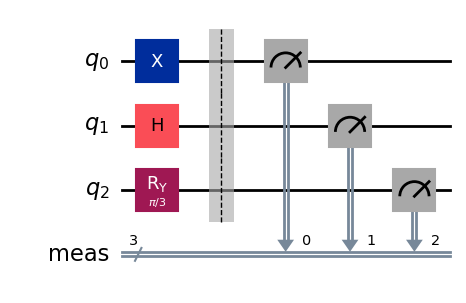

In [2]:
circuit = QuantumCircuit(3)

##### YOUR CODE GOES HERE #####
circuit.x(0)
circuit.h(1)
circuit.ry(pi/3, 2)

circuit.measure_all()
circuit.draw(output='mpl')

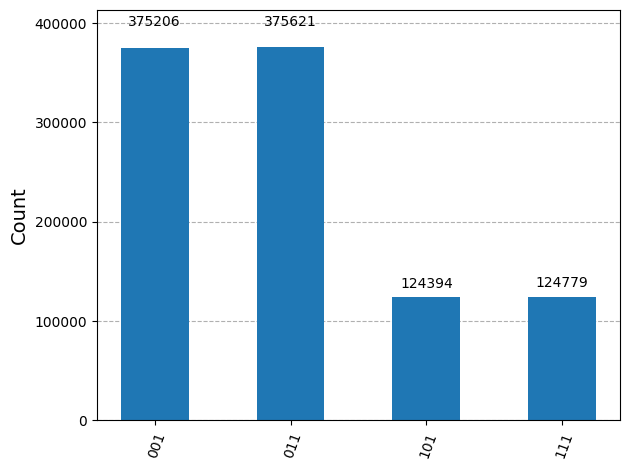

In [3]:
# UPDATE: Code updated after recording to resolve breaking changes from Qiskit 1.0
from qiskit.providers.basic_provider import BasicProvider
simulator = BasicProvider().get_backend('basic_simulator')
compiled_circuit = transpile(circuit, simulator)
shots = 1000000
result = simulator.run(compiled_circuit, shots=shots).result()
plot_histogram(result.get_counts())

In [4]:
# UPDATE: Code updated after recording to resolve breaking changes from Qiskit 1.0
circuit.remove_final_measurements()  # no measurements allowed
from qiskit.quantum_info import Statevector
statevector = Statevector(circuit)
array_to_latex(statevector)

<IPython.core.display.Latex object>

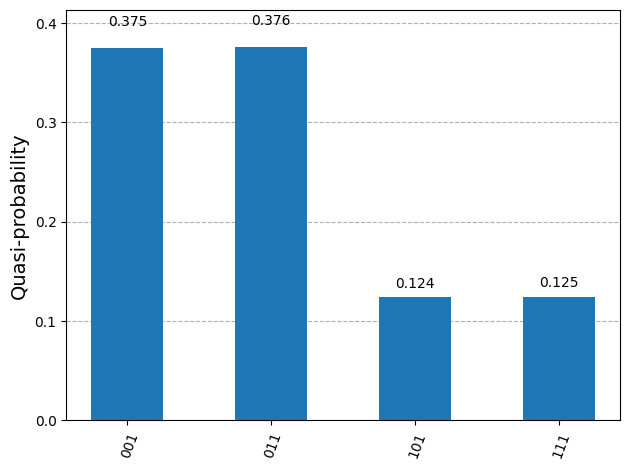

In [5]:
probabilities = {state: (count / shots) for (state, count) in result.get_counts().items()}
plot_histogram(probabilities)

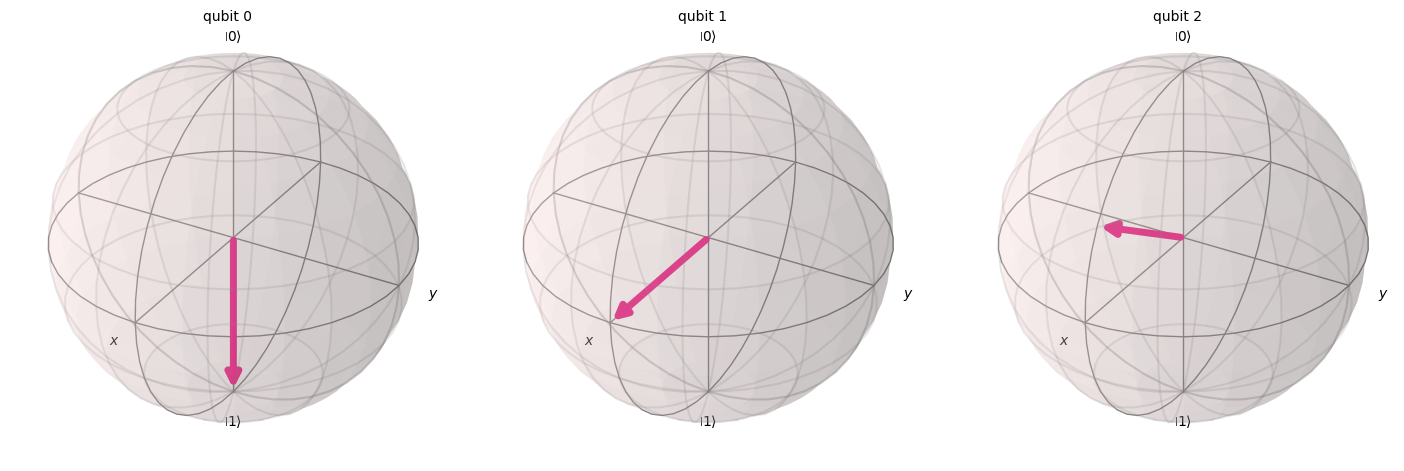

In [6]:
plot_bloch_multivector(statevector)